# Task 40: Bayesian Neural-Network Architecture Tuning

Evaluate layer and width choices with a manually coded Gaussian-process surrogate and expected improvement. Tune on validation F1, then evaluate the selected architecture on held-out test data.

Search history: [((8,), 0.906), ((16,), 0.848), ((16, 12, 8), 0.868), ((12, 8), 0.889), ((24, 12), 0.857), ((16, 8), 0.732), ((24,), 0.901)]
Selected architecture: (8,)
{'accuracy': 0.7377049180327869, 'precision': 0.7575757575757576, 'recall': 0.7575757575757576, 'f1': 0.7575757575757576}


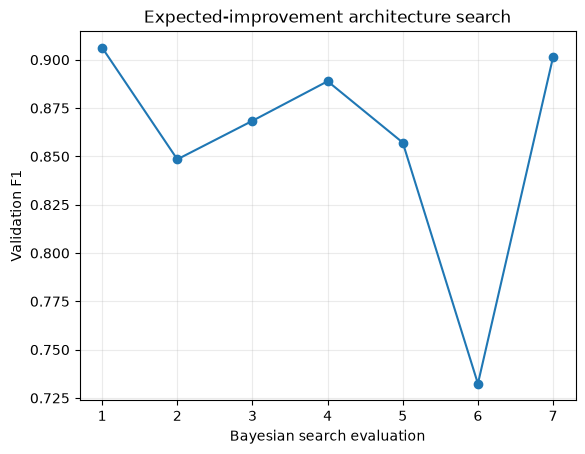

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_options = [Path('heart.csv'), Path('Task_40_Bayesian_Neural_Network_Architecture_Tuning/heart.csv'), Path('Heart_Disease_Tasks/Task_40_Bayesian_Neural_Network_Architecture_Tuning/heart.csv')]
data = pd.read_csv(next(path for path in csv_options if path.is_file())).drop_duplicates().reset_index(drop=True)
feature_names = [name for name in ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal'] if name in data]
X, y = data[feature_names].to_numpy(float), data['target'].to_numpy(int)


def stratified_partition(labels, fraction, seed):
    rng = np.random.default_rng(seed)
    first, second = [], []
    for label in np.unique(labels):
        indices = np.flatnonzero(labels == label)
        rng.shuffle(indices)
        cut = int(round(fraction * len(indices)))
        first.extend(indices[:cut])
        second.extend(indices[cut:])
    rng.shuffle(first)
    rng.shuffle(second)
    return np.array(first), np.array(second)


train_val_idx, test_idx = stratified_partition(y, 0.8, 40)
train_local, validation_local = stratified_partition(y[train_val_idx], 0.75, 41)
train_idx, validation_idx = train_val_idx[train_local], train_val_idx[validation_local]
X_train, X_validation, X_test = X[train_idx], X[validation_idx], X[test_idx]
y_train, y_validation, y_test = y[train_idx], y[validation_idx], y[test_idx]
mean, scale = X_train.mean(axis=0), X_train.std(axis=0)
scale[scale == 0] = 1.0
X_train, X_validation, X_test = (X_train - mean) / scale, (X_validation - mean) / scale, (X_test - mean) / scale


class ManualMLP:
    def __init__(self, hidden, seed=40):
        self.hidden, self.seed = hidden, seed

    def fit(self, x, labels, epochs=65, batch_size=32, rate=0.01, dropout=0.15):
        rng = np.random.default_rng(self.seed)
        sizes = (x.shape[1], *self.hidden, 1)
        self.weights = [rng.normal(0, np.sqrt(2 / sizes[i]), (sizes[i], sizes[i + 1])) for i in range(len(sizes) - 1)]
        self.biases = [np.zeros((1, sizes[i + 1])) for i in range(len(sizes) - 1)]
        hidden_count = len(self.hidden)
        self.gamma = [np.ones((1, width)) for width in self.hidden]
        self.beta = [np.zeros((1, width)) for width in self.hidden]
        self.running_mean = [np.zeros((1, width)) for width in self.hidden]
        self.running_var = [np.ones((1, width)) for width in self.hidden]
        targets = labels.reshape(-1, 1).astype(float)
        self.loss_history = []
        for _ in range(epochs):
            order = rng.permutation(len(x))
            epoch_loss = 0.0
            for start in range(0, len(x), batch_size):
                indices = order[start:start + batch_size]
                xb, yb = x[indices], targets[indices]
                activations, caches = [xb], []
                for layer in range(hidden_count):
                    z = activations[-1] @ self.weights[layer] + self.biases[layer]
                    mu, var = z.mean(axis=0, keepdims=True), z.var(axis=0, keepdims=True)
                    inv_std = 1 / np.sqrt(var + 1e-5)
                    normalized = (z - mu) * inv_std
                    scaled = self.gamma[layer] * normalized + self.beta[layer]
                    self.running_mean[layer] = 0.9 * self.running_mean[layer] + 0.1 * mu
                    self.running_var[layer] = 0.9 * self.running_var[layer] + 0.1 * var
                    activated = np.maximum(scaled, 0)
                    mask = (rng.random(activated.shape) >= dropout).astype(float) / (1 - dropout) if dropout and len(indices) > 1 else None
                    if mask is not None:
                        activated *= mask
                    caches.append((normalized, inv_std, scaled, mask))
                    activations.append(activated)
                logits = activations[-1] @ self.weights[-1] + self.biases[-1]
                probabilities = 1 / (1 + np.exp(-np.clip(logits, -35, 35)))
                epoch_loss += float(-np.sum(yb * np.log(probabilities + 1e-12) + (1 - yb) * np.log(1 - probabilities + 1e-12)))
                gradient = (probabilities - yb) / len(indices)
                dw, db = [None] * len(self.weights), [None] * len(self.biases)
                dgamma, dbeta = [None] * hidden_count, [None] * hidden_count
                dw[-1] = activations[-1].T @ gradient
                db[-1] = gradient.sum(axis=0, keepdims=True)
                gradient = gradient @ self.weights[-1].T
                for layer in range(hidden_count - 1, -1, -1):
                    normalized, inv_std, scaled, mask = caches[layer]
                    if mask is not None:
                        gradient *= mask
                    gradient *= scaled > 0
                    dgamma[layer] = np.sum(gradient * normalized, axis=0, keepdims=True)
                    dbeta[layer] = gradient.sum(axis=0, keepdims=True)
                    normalized_gradient = gradient * self.gamma[layer]
                    gradient = inv_std / len(indices) * (len(indices) * normalized_gradient - normalized_gradient.sum(axis=0, keepdims=True) - normalized * np.sum(normalized_gradient * normalized, axis=0, keepdims=True))
                    dw[layer] = activations[layer].T @ gradient
                    db[layer] = gradient.sum(axis=0, keepdims=True)
                    gradient = gradient @ self.weights[layer].T
                for layer in range(len(self.weights)):
                    self.weights[layer] -= rate * dw[layer]
                    self.biases[layer] -= rate * db[layer]
                for layer in range(hidden_count):
                    self.gamma[layer] -= rate * dgamma[layer]
                    self.beta[layer] -= rate * dbeta[layer]
            self.loss_history.append(epoch_loss / len(x))
        return self

    def predict_proba(self, x):
        activation = x
        for layer in range(len(self.hidden)):
            z = activation @ self.weights[layer] + self.biases[layer]
            normalized = (z - self.running_mean[layer]) / np.sqrt(self.running_var[layer] + 1e-5)
            activation = np.maximum(self.gamma[layer] * normalized + self.beta[layer], 0)
        logits = activation @ self.weights[-1] + self.biases[-1]
        return (1 / (1 + np.exp(-np.clip(logits, -35, 35)))).ravel()


def manual_f1(actual, predicted):
    tp = np.sum((actual == 1) & (predicted == 1))
    fp = np.sum((actual == 0) & (predicted == 1))
    fn = np.sum((actual == 1) & (predicted == 0))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return float(2 * precision * recall / (precision + recall)) if precision + recall else 0.0


architectures = [(8,), (16,), (24,), (12, 8), (16, 8), (24, 12), (16, 12, 8)]
model_cache = {}


def validation_objective(architecture):
    model = ManualMLP(architecture, seed=40 + sum(architecture)).fit(X_train, y_train)
    score = manual_f1(y_validation, (model.predict_proba(X_validation) >= 0.5).astype(int))
    model_cache[architecture] = model
    return score


def encode_architecture(architecture):
    widths = list(architecture[:3]) + [0] * (3 - len(architecture[:3]))
    return np.array([len(architecture) / 3, *[width / 32 for width in widths]])


observations = []
remaining = architectures.copy()
for architecture in architectures[:2]:
    observations.append({'architecture': architecture, 'score': validation_objective(architecture)})
    remaining.remove(architecture)
while remaining and len(observations) < len(architectures):
    observed_x = np.vstack([encode_architecture(row['architecture']) for row in observations])
    observed_y = np.array([row['score'] for row in observations])
    candidate_x = np.vstack([encode_architecture(architecture) for architecture in remaining])
    kernel = np.exp(-0.5 * np.sum((observed_x[:, None] - observed_x[None, :]) ** 2, axis=2)) + np.eye(len(observed_y)) * 1e-6
    cross = np.exp(-0.5 * np.sum((candidate_x[:, None] - observed_x[None, :]) ** 2, axis=2))
    inverse = np.linalg.inv(kernel)
    mean = cross @ inverse @ observed_y
    variance = np.maximum(1 - np.sum((cross @ inverse) * cross, axis=1), 1e-9)
    std = np.sqrt(variance)
    z = (mean - observed_y.max() - 0.01) / std
    cdf = 0.5 * (1 + np.vectorize(math.erf)(z / np.sqrt(2)))
    pdf = np.exp(-0.5 * z * z) / np.sqrt(2 * np.pi)
    expected_improvement = (mean - observed_y.max() - 0.01) * cdf + std * pdf
    choice = int(np.argmax(expected_improvement))
    architecture = remaining.pop(choice)
    observations.append({'architecture': architecture, 'score': validation_objective(architecture)})

best = max(observations, key=lambda row: row['score'])
best_model = model_cache[best['architecture']]
probabilities = best_model.predict_proba(X_test)
predictions = (probabilities >= 0.5).astype(int)
tp = np.sum((y_test == 1) & (predictions == 1)); tn = np.sum((y_test == 0) & (predictions == 0))
fp = np.sum((y_test == 0) & (predictions == 1)); fn = np.sum((y_test == 1) & (predictions == 0))
precision = tp / (tp + fp) if tp + fp else 0; recall = tp / (tp + fn) if tp + fn else 0
print('Search history:', [(row['architecture'], round(row['score'], 3)) for row in observations])
print('Selected architecture:', best['architecture'])
print({'accuracy': float((tp + tn) / len(y_test)), 'precision': float(precision), 'recall': float(recall), 'f1': manual_f1(y_test, predictions)})
plt.plot(range(1, len(observations) + 1), [row['score'] for row in observations], marker='o')
plt.xlabel('Bayesian search evaluation'); plt.ylabel('Validation F1'); plt.title('Expected-improvement architecture search'); plt.grid(alpha=0.25); plt.show()